In [3]:
#Problem Statement - A quantum circuit can produce different measurement outcomes depending 
#on the gates applied to a qubit. 

In [ ]:
 # A single-qubit quantum circuit. 

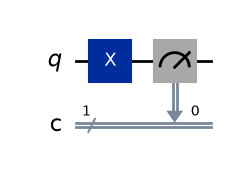

In [15]:
from qiskit import QuantumCircuit
A = QuantumCircuit(1,1)
A.x(0)
A.measure(0, 0)
A.draw("mpl")

In [16]:
print("Circuit A predictions - 1")

Circuit A predictions - 1


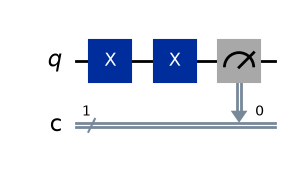

In [17]:
B = QuantumCircuit(1,1)
B.x(0)
B.x(0)
B.measure(0, 0)
B.draw("mpl")

In [18]:
print("Circuit B predictions - 0")

Circuit B predictions - 0


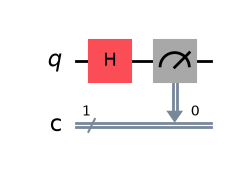

In [19]:
C = QuantumCircuit(1,1)
C.h(0)
C.measure(0, 0)
C.draw("mpl")

In [20]:
print("Circuit C predictions - 50% 0 and 50% 1")

Circuit C predictions - 50% 0 and 50% 1


In [23]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit import transpile

# Create a quantum simulator
simulator = AerSimulator()
shots = 100

# Execute each circuit for 100 shots
def run_circuit(qc):
    compiled_circuit = transpile(qc, simulator)
    result = simulator.run(
        compiled_circuit, shots=shots
    ).result()
    return result.get_counts()

counts_a = run_circuit(A)
counts_b = run_circuit(B)
counts_c = run_circuit(C)


In [24]:
print("\nActual Measurement Results:")
print("Circuit A:", counts_a)
print("Circuit B:", counts_b)
print("Circuit C:", counts_c)


Actual Measurement Results:
Circuit A: {'1': 100}
Circuit B: {'0': 100}
Circuit C: {'0': 48, '1': 52}


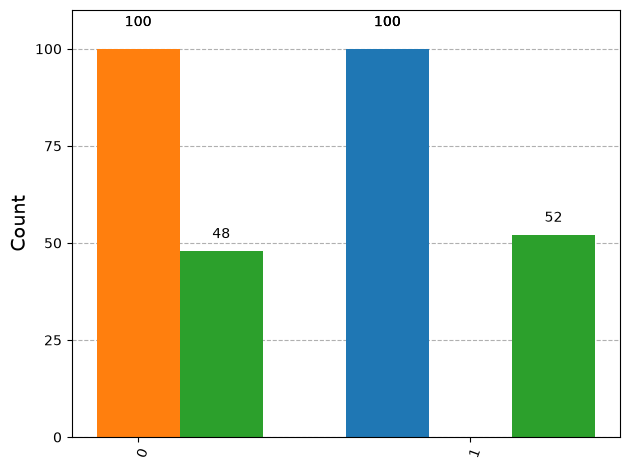

In [36]:
# Plot the histograms
from qiskit.visualization import plot_histogram
plot_histogram([counts_a, counts_b, counts_c])

In [31]:
# Compare predictions with actual results
print("\nComparison:")
print("Circuit A: Expected 1, observed counts:", counts_a)
print("Circuit B: Expected 0, observed counts:", counts_b)
print("Circuit C: Expected approximately 50/50, observed counts:", counts_c)


Comparison:
Circuit A: Expected 1, observed counts: {'1': 100}
Circuit B: Expected 0, observed counts: {'0': 100}
Circuit C: Expected approximately 50/50, observed counts: {'0': 48, '1': 52}
